<a href="https://colab.research.google.com/github/amanpoonia/SBeta_preparation/blob/main/Backtesting/WF_fundamentals.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
'''
AIM: Understand walkforward framework for backtesting

Backtest a strategy(MA crossover : Long when when price closes above the moving average and short when it falls below)
Test settings
Performance metrics
'''

/tmp/ipykernel_1343/3599741292.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  data = yf.download('^GSPC', start=start_date, end=end_date)
[*********************100%***********************]  1 of 1 completed


Price             Close         High          Low         Open      Volume
Ticker            ^GSPC        ^GSPC        ^GSPC        ^GSPC       ^GSPC
Date                                                                      
2020-01-02  3257.850098  3258.139893  3235.530029  3244.669922  3459930000
2020-01-03  3234.850098  3246.149902  3222.340088  3226.360107  3484700000
2020-01-06  3246.280029  3246.840088  3214.639893  3217.550049  3702460000
2020-01-07  3237.179932  3244.909912  3232.429932  3241.860107  3435910000
2020-01-08  3253.050049  3267.070068  3236.669922  3238.590088  3726840000


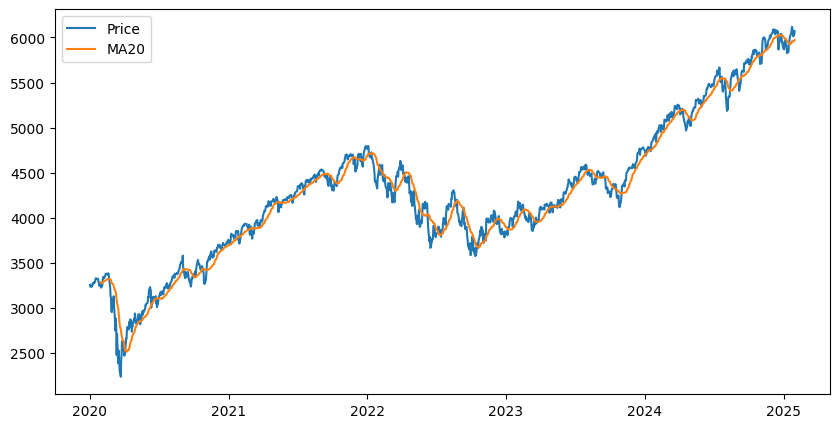

Ticker            ^GSPC         MA20  buy/sell
Date                                          
2020-01-02  3257.850098          NaN       NaN
2020-01-03  3234.850098          NaN       NaN
2020-01-06  3246.280029          NaN       NaN
2020-01-07  3237.179932          NaN       NaN
2020-01-08  3253.050049          NaN       NaN
2020-01-09  3274.699951          NaN       NaN
2020-01-10  3265.350098          NaN       NaN
2020-01-13  3288.129883          NaN       NaN
2020-01-14  3283.149902          NaN       NaN
2020-01-15  3289.290039          NaN       NaN
2020-01-16  3316.810059          NaN       NaN
2020-01-17  3329.620117          NaN       NaN
2020-01-21  3320.790039          NaN       NaN
2020-01-22  3321.750000          NaN       NaN
2020-01-23  3325.540039          NaN       NaN
2020-01-24  3295.469971          NaN       NaN
2020-01-27  3243.629883          NaN       NaN
2020-01-28  3276.239990          NaN       NaN
2020-01-29  3273.399902          NaN       NaN
2020-01-30  3

In [1]:
import pandas as pd
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt

start_date = '2020-01-01'
end_date = '2025-01-31'

data = yf.download('^GSPC', start=start_date, end=end_date)
print(data.head())

#rolling average of the last 20 days
price = data['Close'].copy()

price['MA20'] = price['^GSPC'].rolling(20).mean()

#plotting MA with prices
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.legend()
plt.show()


#trading, trades at crossover
price['buy/sell'] = np.where(price['^GSPC'] > price['MA20'], 1, -1).astype(float)
#price['sell'] = np.where(price['^GSPC'] < price['MA20'], 1, 0)
price.loc[price['MA20'].isna(), 'buy/sell'] = np.nan


print(price.head(21))

Ticker            ^GSPC         MA20  buy/sell  pos   prev_close       ret  \
Date                                                                         
2020-02-04  3297.590088  3282.489490       1.0 -1.0  3248.919922  0.014869   
2020-02-05  3334.689941  3287.364990       1.0  1.0  3297.590088  0.011188   
2020-02-06  3345.780029  3292.001489       1.0  1.0  3334.689941  0.003320   
2020-02-07  3327.709961  3294.651990       1.0  1.0  3345.780029 -0.005415   
2020-02-10  3352.090088  3298.988989       1.0  1.0  3327.709961  0.007300   
2020-02-11  3357.750000  3302.469995       1.0  1.0  3352.090088  0.001687   
2020-02-12  3379.449951  3307.284998       1.0  1.0  3357.750000  0.006442   
2020-02-13  3373.939941  3311.517493       1.0  1.0  3379.449951 -0.001632   
2020-02-14  3380.159912  3314.684985       1.0  1.0  3373.939941  0.001842   
2020-02-18  3370.290039  3316.718481       1.0  1.0  3380.159912 -0.002924   

Ticker      ret_simple  ret_strat  cum_ret_strat  
Date        

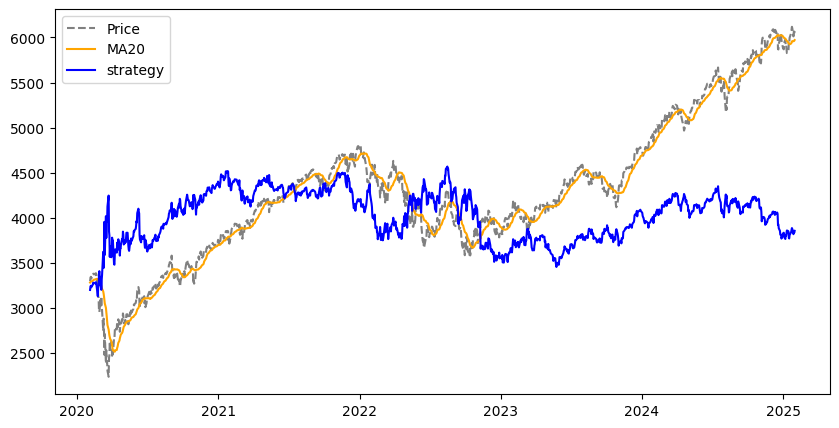

In [4]:
from matplotlib.lines import lineStyles
from numpy._core.function_base import linspace
'''
Correctly aligning signal and return data

Signal is generated on time t
Trade(buy/sell) on time t
Held from time t to t+1
return on this trade at t+1.

ret_trade(t+1) = signal(t) * [P(t+1)-P(t)]/P(t)
'''

# position held over the day t
price['pos'] = price['buy/sell'].shift(1)

# entry price
price['prev_close'] = price['^GSPC'].shift(1)

# return of holding it for a day
price['ret'] = np.log(price['^GSPC']/price['prev_close'])
price['ret_simple'] = price['^GSPC'].pct_change()

#return of the strategy
price['ret_strat'] = np.log1p(price['pos'] * price['ret_simple'])

price.dropna(inplace=True)

# portfolio value
price['cum_ret_strat'] = price['prev_close'].iloc[0] * np.exp(price['ret_strat'].cumsum())
print(price.head(10))

plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price', color = 'gray', linestyle = '--')
plt.plot(price['MA20'], label='MA20', color = 'orange')
plt.plot(price['cum_ret_strat'], label='strategy', color = 'blue')
plt.legend()
plt.show()

In [3]:
price

Ticker,^GSPC,MA20,buy/sell,pos,prev_close,ret_trade
Date,,,,,,
2020-01-02,3257.850098,NaN,NaN,NaN,NaN,NaN
2020-01-03,3234.850098,NaN,NaN,NaN,3257.850098,NaN
2020-01-06,3246.280029,NaN,NaN,NaN,3234.850098,NaN
2020-01-07,3237.179932,NaN,NaN,NaN,3246.280029,NaN
2020-01-08,3253.050049,NaN,NaN,NaN,3237.179932,NaN
...,...,...,...,...,...,...
2025-01-24,6101.240234,5959.818018,1.0,1.0,6118.709961,-0.002859
2025-01-27,6012.279785,5958.430005,1.0,1.0,6101.240234,-0.014688
2025-01-28,6067.700195,5959.935522,1.0,1.0,6012.279785,0.009176


Ticker            ^GSPC         MA20  buy/sell       ret  ret_strat  \
Date                                                                  
2020-01-30  3283.659912  3280.837000         1  0.003129  -0.003129   
2020-01-31  3225.520020  3279.220496        -1 -0.017864  -0.017864   
2020-02-03  3248.919922  3279.923987        -1  0.007228  -0.007228   
2020-02-04  3297.590088  3282.489490         1  0.014869  -0.014869   
2020-02-05  3334.689941  3287.364990         1  0.011188   0.011188   
2020-02-06  3345.780029  3292.001489         1  0.003320   0.003320   
2020-02-07  3327.709961  3294.651990         1 -0.005415  -0.005415   
2020-02-10  3352.090088  3298.988989         1  0.007300   0.007300   

Ticker      cum_ret_strat  
Date                       
2020-01-30    3273.399902  
2020-01-31    3215.441672  
2020-02-03    3192.282892  
2020-02-04    3145.166988  
2020-02-05    3180.551991  
2020-02-06    3191.129466  
2020-02-07    3173.894643  
2020-02-10    3197.147857  


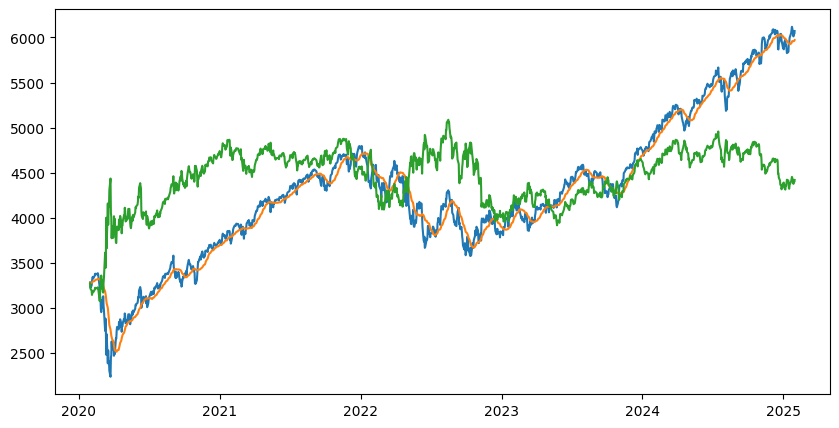

In [2]:
'''
Correctly aligning signal and return data

Signal is generated on time t
Trade(buy/sell) on time t
Held from time t to t+1
return on this trade at t+1.

ret_trade(t+1) = signal(t) * [P(t+1)-P(t)]/P(t)
'''


price['ret'] = np.log(price['^GSPC'] / price['^GSPC'].shift(1))
price.dropna(inplace=True)
price

# Strategy returns are
# ret_strat(t) = [buy/sell signal(t-1)] * [ret(t)]

price['ret_strat'] = np.where(price['buy/sell'].shift(1) == 1, price['ret'], -price['ret'])
#price['cum_ret_strat'] = price['^GSPC'][0] * (1 + price['ret_strat'].cumsum())
price['cum_ret_strat'] = price['^GSPC'].iloc[0] * np.exp(price['ret_strat'].cumsum())
print(price.head(8))

#plot
plt.figure(figsize=(10, 5))
plt.plot(price['^GSPC'], label='Price')
plt.plot(price['MA20'], label='MA20')
plt.plot(price['cum_ret_strat'], label='strategy')

In [4]:
# Trade happens

price['pos_change'] = price['buy/sell'] != price['buy/sell'].shift(1)
#unique id to each trade
price['trade_no'] = price['pos_change'].cumsum()

#metrics
metrics = price.groupby('trade_no').agg(
    position = ('buy/sell', 'first'),
    days_in_trade = ('buy/sell', 'count'),
    ret_trade = ('ret_strat', 'sum')
).reset_index(drop=True)

metrics

,position,days_in_trade,ret_trade
0,1,1,-0.003129
1,-1,2,-0.025093
2,1,13,-0.002764
3,-1,30,0.225380
4,1,26,0.006677
...,...,...,...
114,1,29,-0.004685
115,-1,4,-0.047142
116,1,2,-0.011388
117,-1,11,0.010541


In [4]:

# 1. Identify when the signal changes (to isolate each trade)
# We compare the current signal with the previous day's signal
price['position_change'] = price['buy/sell'] != price['buy/sell'].shift(1)

# 2. Assign a unique trade ID to each contiguous trading period
price['trade_id'] = price['position_change'].cumsum()

# 3. Group by the unique trade ID to aggregate metrics for each trade
trade_metrics = price.groupby('trade_id').agg(
    position=('buy/sell', 'first'),
    days_in_trade=('buy/sell', 'count'),
    trade_return=('ret_strat', 'sum')
).reset_index(drop=True)

# 4. Separate Long (Buy) and Short (Sell) metrics
long_trades = trade_metrics[trade_metrics['position'] == 1]
short_trades = trade_metrics[trade_metrics['position'] == -1]

# 5. Display the performance metrics comparison
print("=== PERFORMANCE METRICS ===")
print(f"Total Long Trades: {len(long_trades)}")
print(f"Total Short Trades: {len(short_trades)}")
print(f"Total Days Spent Long: {long_trades['days_in_trade'].sum()} days")
print(f"Total Days Spent Short: {short_trades['days_in_trade'].sum()} days")
print(f"Cumulative Long Return (Log): {long_trades['trade_return'].sum():.4f}")
print(f"Cumulative Short Return (Log): {short_trades['trade_return'].sum():.4f}")
print(f"Avg Days in Long Trade: {long_trades['days_in_trade'].mean():.1f} days")
print(f"Avg Days in Short Trade: {short_trades['days_in_trade'].mean():.1f} days")


=== PERFORMANCE METRICS ===
Total Long Trades: 28
Total Short Trades: 28
Total Days Spent Long: 286 days
Total Days Spent Short: 216 days
Cumulative Long Return (Log): 0.0382
Cumulative Short Return (Log): -0.0559
Avg Days in Long Trade: 10.2 days
Avg Days in Short Trade: 7.7 days


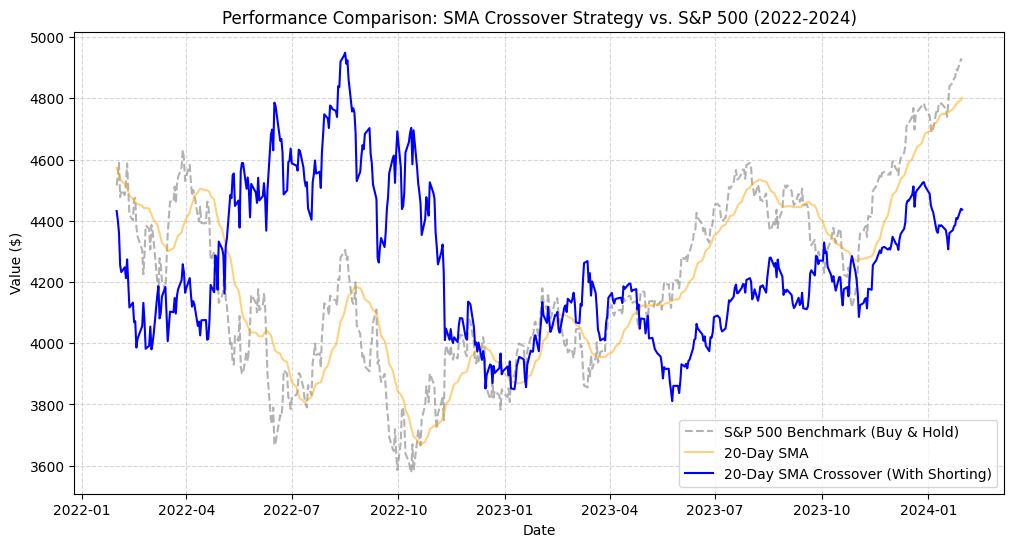

In [5]:
# Plot the strategy equity curve compared to the S&P 500 Buy & Hold
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))
# S&P 500 Benchmark (Buy & Hold from starting day)
plt.plot(price['^GSPC'], label='S&P 500 Benchmark (Buy & Hold)', color='gray', alpha=0.6, linestyle='--')
# 20-Day SMA Line
plt.plot(price['MA20'], label='20-Day SMA', color='orange', alpha=0.5)
# Cumulative Strategy Equity Curve (Starting at same initial index value)
plt.plot(price['cum_ret_strat'], label='20-Day SMA Crossover (With Shorting)', color='blue', linewidth=1.5)

plt.title('Performance Comparison: SMA Crossover Strategy vs. S&P 500 (2022-2024)')
plt.xlabel('Date')
plt.ylabel('Value ($)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [6]:
# Walk-Forward Optimization Framework
import pandas as pd
import numpy as np

def evaluate_strategy(df, sma_length):
    """Simulates the SMA crossover strategy and returns the total log return."""
    temp = df.copy()
    temp['MA'] = temp['^GSPC'].rolling(sma_length).mean()
    temp['signal'] = np.where(temp['^GSPC'] > temp['MA'], 1, -1)
    temp['ret'] = np.log(temp['^GSPC'] / temp['^GSPC'].shift(1))
    # Strategy returns based on previous day's signal
    temp['ret_strat'] = temp['signal'].shift(1) * temp['ret']
    return temp['ret_strat'].sum()

# Define parameter space to optimize
sma_candidates = [10, 20, 30, 50]

# We will use a sliding window approach:
# - In-Sample (IS) training window: 6 months
# - Out-of-Sample (OOS) testing window: 3 months

# Let's define the dates
dates = price.index
start_idx = 0
is_window_size = 126  # ~6 months of trading days
oos_window_size = 63  # ~3 months of trading days

oos_results = []

print("=== WALK-FORWARD RUNS ===")
while start_idx + is_window_size + oos_window_size < len(price):
    # Slice training (In-Sample) data
    is_data = price.iloc[start_idx : start_idx + is_window_size]
    # Slice testing (Out-of-Sample) data
    oos_data = price.iloc[start_idx + is_window_size : start_idx + is_window_size + oos_window_size].copy()

    # Step 1: Optimize parameter In-Sample
    best_sma = None
    best_is_return = -np.inf
    for sma in sma_candidates:
        is_ret = evaluate_strategy(is_data, sma)
        if is_ret > best_is_return:
            best_is_return = is_ret
            best_sma = sma

    # Step 2: Apply the best parameter Out-of-Sample
    # We calculate the OOS returns using the selected 'best_sma'
    oos_data['MA'] = oos_data['^GSPC'].rolling(best_sma).mean()
    oos_data['signal'] = np.where(oos_data['^GSPC'] > oos_data['MA'], 1, -1)
    oos_data['ret'] = np.log(oos_data['^GSPC'] / oos_data['^GSPC'].shift(1))
    oos_data['ret_strat'] = oos_data['signal'].shift(1) * oos_data['ret']

    oos_ret = oos_data['ret_strat'].sum()

    is_start_dt = is_data.index[0].strftime('%Y-%m-%d')
    is_end_dt = is_data.index[-1].strftime('%Y-%m-%d')
    oos_start_dt = oos_data.index[0].strftime('%Y-%m-%d')
    oos_end_dt = oos_data.index[-1].strftime('%Y-%m-%d')

    print(f"IS ({is_start_dt} to {is_end_dt}) -> Best SMA: {best_sma} (IS Ret: {best_is_return:.4f})")
    print(f"  -> OOS ({oos_start_dt} to {oos_end_dt}) -> Applied SMA {best_sma} (OOS Ret: {oos_ret:.4f})\n")

    oos_results.append(oos_data['ret_strat'])

    # Shift the window forward by the OOS step size
    start_idx += oos_window_size

# Combine all out-of-sample performance periods
if oos_results:
    all_oos_returns = pd.concat(oos_results).dropna()
    cum_oos_return = np.exp(all_oos_returns.cumsum()) - 1
    print(f"=== WALK-FORWARD OUT-OF-SAMPLE RESULTS ===")
    print(f"Cumulative Out-of-Sample Return: {cum_oos_return.iloc[-1]*100:.2f}%")


=== WALK-FORWARD RUNS ===
IS (2022-01-31 to 2022-08-01) -> Best SMA: 20 (IS Ret: 0.2025)
  -> OOS (2022-08-02 to 2022-10-28) -> Applied SMA 20 (OOS Ret: 0.0074)

IS (2022-05-02 to 2022-10-28) -> Best SMA: 30 (IS Ret: 0.2012)
  -> OOS (2022-10-31 to 2023-01-31) -> Applied SMA 30 (OOS Ret: -0.0583)

IS (2022-08-02 to 2023-01-31) -> Best SMA: 30 (IS Ret: 0.1196)
  -> OOS (2023-02-01 to 2023-05-02) -> Applied SMA 30 (OOS Ret: 0.0062)

IS (2022-10-31 to 2023-05-02) -> Best SMA: 20 (IS Ret: -0.0200)
  -> OOS (2023-05-03 to 2023-08-02) -> Applied SMA 20 (OOS Ret: 0.0552)

IS (2023-02-01 to 2023-08-02) -> Best SMA: 50 (IS Ret: 0.0783)
  -> OOS (2023-08-03 to 2023-10-31) -> Applied SMA 50 (OOS Ret: 0.0709)

=== WALK-FORWARD OUT-OF-SAMPLE RESULTS ===
Cumulative Out-of-Sample Return: 8.47%
